In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

In [2]:
data = pd.read_csv('insurance-checkpoint.csv')
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# EDA

In [3]:
# data.shape
# data.info()
# data.describe() 
# data.isnull().sum() 
# data.columns
!pip install seaborn


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


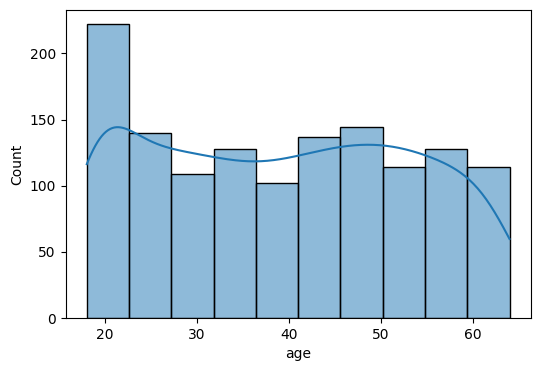

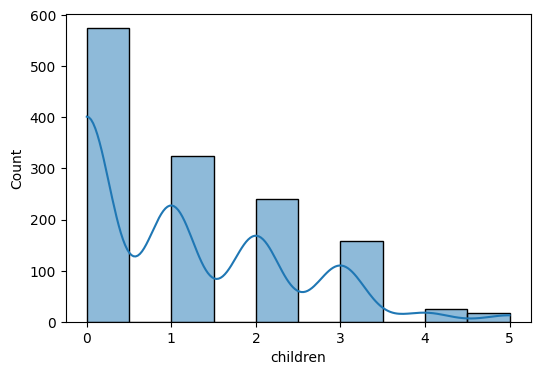

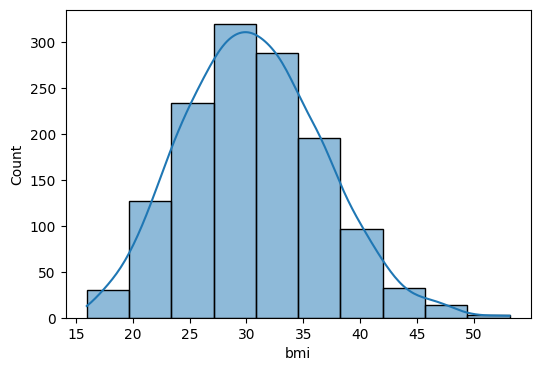

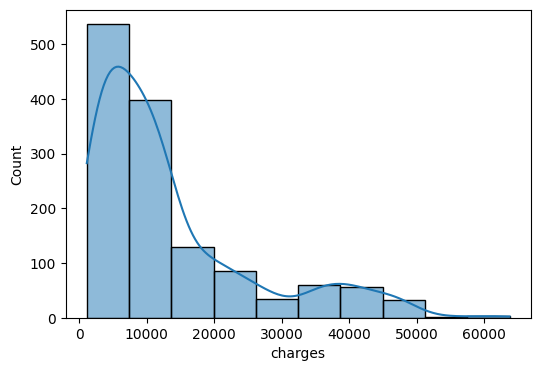

In [4]:
numeric_columns = ['age','children', 'bmi', 'charges'] 
for col in numeric_columns:
    plt.figure(figsize=(6,4)) 
    sns.histplot(data[col],kde=True,bins=10)   

<Axes: xlabel='count', ylabel='smoker'>

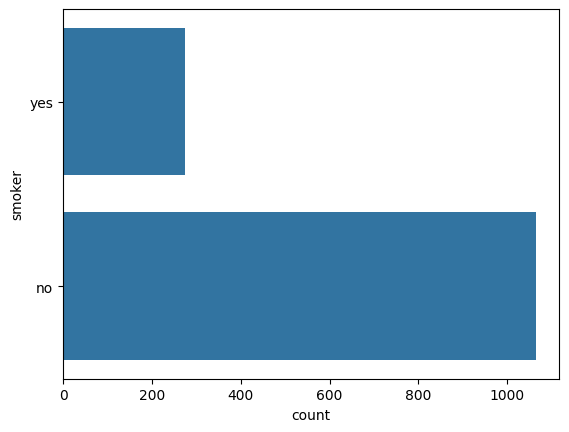

In [5]:
# sns.countplot(x = data['children'])  
# sns.countplot(data['sex']) 
sns.countplot(data['smoker'])  

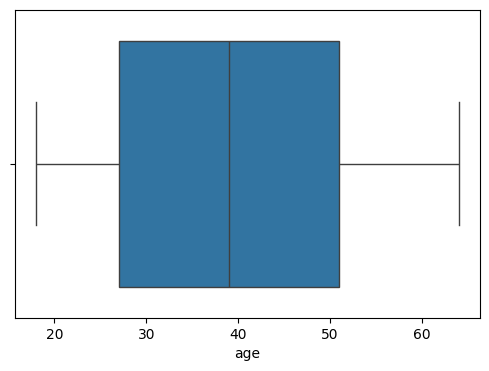

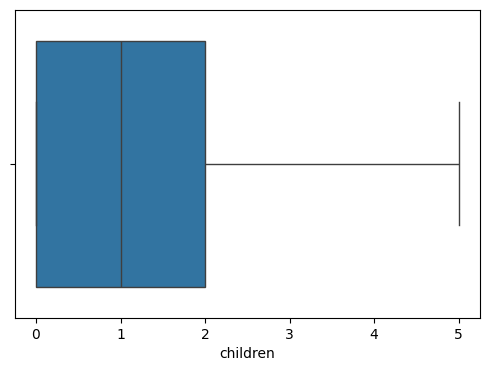

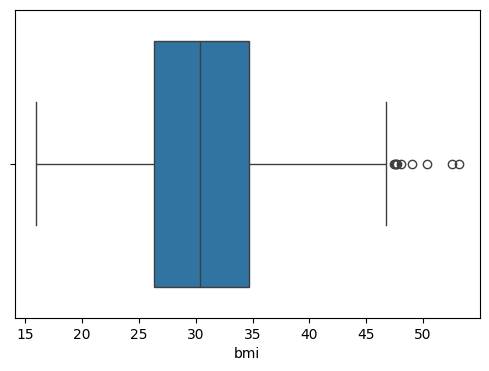

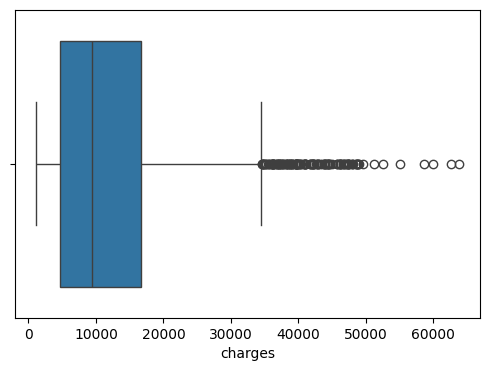

In [6]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=data[col])     

<Axes: >

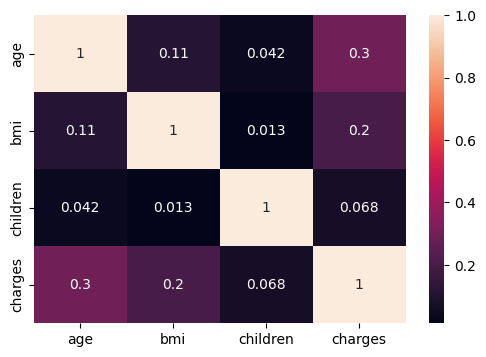

In [7]:
plt.figure(figsize=(6,4))
sns.heatmap(data.corr(numeric_only=True),annot=True)

# Data Cleaning and preprocessing

In [8]:
clean_data = data.copy() 
clean_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
clean_data.shape
clean_data.drop_duplicates(inplace=True)
clean_data.shape

(1337, 7)

In [10]:
clean_data.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

In [11]:
clean_data['sex'].value_counts() 

sex
male      675
female    662
Name: count, dtype: int64

# for using in ml the data should be in numeric form  sowe rae converting male to 0 female to 1 

In [12]:
clean_data['sex'] = clean_data['sex'].map({"male": 0, "female": 1})

In [13]:
clean_data['smoker']  =  clean_data['smoker'].map({"no":0,"yes":1})

In [14]:
clean_data.rename(
    columns = {
            'sex':'isFemale',
            'smoker':'isSmoker'
            }
,inplace=True)


In [15]:
clean_data['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [16]:
clean_data = pd.get_dummies(clean_data,columns=['region'])  

In [17]:
clean_data = clean_data.astype(int)
clean_data

,age,isFemale,bmi,children,isSmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0
1334,18,1,31,0,0,2205,1,0,0,0
1335,18,1,36,0,0,1629,0,0,1,0
1336,21,1,25,0,0,2007,0,0,0,1


# Feature Engineering and Extraction

In [18]:
clean_data['bmi_category'] = pd.cut(
    clean_data['bmi'],
    bins=[0,18.5,24.9,28.9,float('inf')],
    labels=['Underweight','Normal','Overweight','Obese'] 
) 

In [19]:
clean_data

,age,isFemale,bmi,children,isSmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,0,1,Overweight
1,18,0,33,1,0,1725,0,0,1,0,Obese
2,28,0,33,3,0,4449,0,0,1,0,Obese
3,33,0,22,0,0,21984,0,1,0,0,Normal
4,32,0,28,0,0,3866,0,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,Obese
1334,18,1,31,0,0,2205,1,0,0,0,Obese
1335,18,1,36,0,0,1629,0,0,1,0,Obese
1336,21,1,25,0,0,2007,0,0,0,1,Overweight


In [20]:
clean_data = pd.get_dummies(clean_data,columns=['bmi_category'])  

In [21]:
clean_data = clean_data.astype(int) 

In [22]:
clean_data.head()

,age,isFemale,bmi,children,isSmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,0,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0


In [23]:
from sklearn.preprocessing import StandardScaler
cols = ['age','bmi','children']
scaler = StandardScaler() 
clean_data[cols]=scaler.fit_transform(clean_data[cols]) 
# !pip install scikit-learn


In [24]:
clean_data.head()

,age,isFemale,bmi,children,isSmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0,0,1,0


In [25]:
from scipy.stats import pearsonr
# pearson correlation calculataion

#list of features to check against target  
selected_features = [
    'age', 'bmi', 'children', 'isFemale', 'isSmoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

correlations = {
    feature: pearsonr(clean_data[feature],clean_data['charges'])[0]
    for feature in selected_features
}

correlation_data = pd.DataFrame(list(correlations.items()) ,columns=['Feature','Pearson Correlation']) 
correlation_data.sort_values(by='Pearson Correlation',ascending=False)   


,Feature,Pearson Correlation
4,isSmoker,0.787234
0,age,0.298309
1,bmi,0.196236
10,bmi_category_Obese,0.177972
6,region_southeast,0.073577
2,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,isFemale,-0.058046
9,bmi_category_Overweight,-0.100127


In [26]:
cat_features = [
    'isFemale', 'isSmoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

In [27]:
from scipy.stats import chi2_contingency

alpha = 0.05

clean_data['charges_bin'] = pd.qcut(clean_data['charges'], q=4, labels=False)
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(clean_data[col], clean_data['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
isSmoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
isFemale,10.258784,0.01649,Reject Null (Keep Feature)
bmi_category_Obese,5.362127,0.147122,Accept Null (Drop Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_Normal,3.708088,0.29476,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)
bmi_category_Overweight,0.767526,0.857218,Accept Null (Drop Feature)


In [28]:
final_data = clean_data[['age', 'isFemale', 'bmi', 'children', 'isSmoker', 'charges','region_southeast','bmi_category_Obese']]
final_data

In [51]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Step 1: Split the data
X = final_data.drop('charges', axis=1)
y = final_data['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Step 2: Train the model
model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 3441.78, 58.64, 830.18,...,23180.78, -445.22, 2793.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['age','isFemale','bmi',...,'isSmoker','region_southeast', 'bmi_category_Obese']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6862
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,7
